# Módulo 3 — Segmentación


In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m3_segmentacion import segmentacion
from modulos.herramientas import graficos, lesion_de_prueba
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

## 1. Cómo segmentamos

Esta parte del programa utiliza la imagen ya mejorada por M1 (sin pelos) y la máscara `valida`, que marca dónde no hay viñeta; y devuelve una máscara binaria de la lesión que cumple: es una sola región, no tiene huecos y no se sale de la zona válida.

Los pasos son los siguientes:
```
imagen mejorada ─► canal B suavizado ─► método (uno de 5) ─► posprocesado ─► máscara
```
donde lo que fuimos variando para la elección del pipeline fue el método.

### Canal B y suavizado

Trabajamos sobre el canal azul, en base al análisis hecho en M1, ya que es el que mejor separa la lesión de la piel (AUC 0,976) entre los 8 canales que se probaron, ya que la melanina absorbe mucho más la luz azul que la roja.

Antes de segmentar, el canal se suaviza con un filtro gaussiano. El pigmento, los puntos y el ruido hacen que el interior de la lesión no sea parejo, y pueda generar bordes dentados en la segmentación. Este filtro se usa en la etapa de segmentación y no en la de mejoramiento ya que la imagen que devuelve M1 no es sólo para segmentar sino también para contar los colores (en M4), y medir la textura (en M5). Si M1 la suavizara, se borraría justamente la red de pigmento que M5 tiene que medir. M1 corrige lo que está mal en la imagen para todos (la viñeta y los pelos).

### Los métodos testeados

**Otsu.** Es un umbral global donde todo lo que es más oscuro que cierto valor es lesión. El valor lo elige el método de Otsu a partir del histograma del canal, buscando minimizar la varianza intraclase y maximizar la interclase para los dos grupos (oscuro y claro). El histograma se arma sólo con los píxeles válidos, porque las esquinas negras de la viñeta lo correrían hacia intensidades oscuras.

**Crecimiento de regiones.** Arranca desde una semilla que decidimos ubicar en el píxel más oscuro de un recuadro central que mide un cuarto de cada lado, ya que en la base de datos que elejimos, la foto siempre se saca apuntando al lunar. No usamos el centro exacto porque podría caer en una zona clara; en cambio, se miran los píxeles que tocan el borde de la región, y entran los que no superan un límite de brillo. El límite está entre el brillo típico de la lesión y el de la piel de esa imagen; con una tolerancia de 0,5 queda justo a mitad de camino, así que entra todo píxel que se parece más a la lesión que a la piel. Haciendo que el límite dependa de cada imagen permite que sirva tanto para una lesión muy oscura como en una clara. El único problema es que si en algún lado la lesión se une a una zona oscura de la piel, la región se escapa por ahí.

**Watershed.** En nuestro caso, la lesión es todo lo oscuro, y piel es lo claro que está conectado con el borde de la zona válida, y todo lo que está fuera de ella. El relieve se "inunda" desde las dos marcas a la vez, y donde las dos aguas se encuentran queda la frontera.

En la primera versión, habíamos definido que la piel era cualquier cosa bien clara, y en lesiones grandes y de poco contraste las partes claras del lunar quedaban marcadas como piel. Además, la marca de lesión era sólo la mancha oscura que contiene la semilla; pero hay lesiones donde lo oscuro está partido en muchas manchas, y adentro de la lesión hay crestas de gradiente más altas que el borde suave con la piel, así que el agua de la lesión quedaba encerrada cerca de la semilla. Pidiendo que la piel esté conectada con el borde y marcando como lesión todo lo oscuro, el Dice pasó de 0,13 a 0,83. Las manchas oscuras sueltas en la piel no molestan, porque el posprocesado se queda con la región del centro.

**k-means.** Para este método no usamos sólo el canal B ya que sería un k-means con dos grupos, que  daría prácticamente el mismo resultado que Otsu. Probamos con 2 grupos (lesión y piel) y con 3, que da lugar por si hay una lesión con dos tonalidades.

**Chan-Vese.** Como es el más lento de los métodos, lo resolvemos sobre la imagen reducida a un cuarto de lado y después agrandamos la máscara. Además, arranca desde el contorno que halló Otsu ya que con el arranque por defecto de la librería (que es un patrón de tablero de ajedrez) se quedaba trabado en lesiones chicas.

### Posprocesado

A todas las salidas le aplicamos:

1. Apertura con un disco (erosión y después dilatación), para borrar todo lo que es más angosto que el disco, como islas chicas o un puente fino hacia un resto de pelo.
2. Cierre con un disco (dilatación y después erosión), para rellenar los huecos del borde.
3. Nos quedamos con la región que contiene el centro de la imagen o, si el centro cayó afuera de todas las regiones, con la más grande.
4. Rellenamos los huecos, ya que una zona blanca dentro del lunar sigue siendo parte del lunar.

Nota: Los radios de los dos discos también se fueron ajustando.

## 2. Cómo comparamos los métodos

**El coeficiente de Dice.** Compara la máscara automática ($A$) con la que dibujaron a mano los autores de PH2 ($B$):

$$\text{Dice} = \frac{2\,|A \cap B|}{|A| + |B|}$$

donde $|A \cap B|$ es la cantidad de píxeles que las dos marcan como lesión. Vale 1 si coinciden exactamente y 0 si no comparten ningún píxel.

**Paso 1: ajustar cada método.** Cada método tiene parámetros, entonces para no comparar un método bien ajustado contra uno mal ajustado, a cada uno le probamos unas pocas combinaciones de valores y nos quedamos con la que da el Dice promedio más alto.

**Paso 2: comparar los cinco métodos ya ajustados.** Con la mejor combinación de cada uno miramos:
- el Dice medio y la mediana (la mediana es útil ya que no varía fácilmente cuando hay pocas imágenes mal segmentadas);
- el desvío y el peor caso;
- cuántas fallas hay. Contamos como falla una imagen con Dice menor a 0,7, que es una convención nuestra para contar los casos malos;
- cuánto tarda cada método por imagen.

**Paso 3: ver si la diferen es real o por casualidad** Si el mejor método ganara por poco en el promedio, podría ser que pasó por suerte. Para eso, para empezar definimos que las diferencias de Dice menores a 0,001 sean empate. En segundo lugar,

**Paso 4: dónde falla cada método.** Separamos las imágenes según cosas que ya sabemos de ellas porque están en los metadatos (diagnóstico, si tienen pelos, si la lesión toca el borde de la foto y si es chica, mediana o grande), y calculamos el Dice promedio de cada método en cada grupo, para ver si hay algún patrón en las fallas (con un análisis nuestro).

**Paso 5: mirar los peores casos,** que serían las tres imágenes con peor Dice del método elegido, con los contornos, para ver dónde falló el programa.

### 2.1 Grilla de parámetros

Los valores rodean a los de partida de `segmentacion.py`:

| Parámetro | Valores | Qué cambia |
|---|---|---|
| `sigma` (suavizado en todos) | 1, 2, 4 px | cuánto se suaviza antes de segmentar |
| radio de apertura y de cierre (operaciones matemáticas en todos) | 3, 6, 10 px (los 9 pares) | tamaño de lo que se borra y de lo que se rellena |
| `tolerancia` (region-growing) | 0,3 / 0,5 / 0,7 del contraste | cuánto más claro que la región puede ser un vecino |
| `marca_lesion`, `marca_piel` (watershed) | (0,1; 0,9), (0,2; 0,8), (0,3; 0,7) | qué tan seguros tienen que ser los marcadores |
| `grupos` (k-means) | 2, 3 | sólo lesión y piel, o lugar para una lesión de dos tonos |
| `mu` (Chan-Vese) | 0,1 / 0,25 / 0,5 | cuánto se penaliza un contorno largo |

Para cada imagen se corre `mejorar()` una sola vez. La salida cruda de cada método se calcula una vez por combinación de sus parámetros, y sobre ella se prueban los nueve pares de radios. Terminan siendo 324 segmentaciones por imagen. El resultado se guarda en `resultados/m3_grilla_entrenamiento.csv`.

In [3]:
SIGMAS = (1, 2, 4)
RADIOS = (3, 6, 10)
GRILLA = {
    "otsu":        [{}],
    "crecimiento": [{"tolerancia": t} for t in (0.3, 0.5, 0.7)],
    "watershed":   [{"marca_lesion": l, "marca_piel": p} for l, p in ((0.1, 0.9), (0.2, 0.8), (0.3, 0.7))],
    "kmeans":      [{"grupos": g} for g in (2, 3)],
    "chan_vese":   [{"mu": mu} for mu in (0.1, 0.25, 0.5)],
}
# Para volver del texto de la tabla ("tolerancia=0.5") al dict de parámetros
PARAMETROS = {(m, segmentacion.describir(p)): p for m, opciones in GRILLA.items() for p in opciones}

ARCHIVO_GRILLA = Path("../../resultados/m3_grilla_entrenamiento.csv")
ARCHIVO_IMAGENES = Path("../../resultados/m3_imagenes_entrenamiento.csv")
tabla = carga_de_datos.leer_tabla_ph2()

if ARCHIVO_GRILLA.exists():
    grilla = pd.read_csv(ARCHIVO_GRILLA, dtype={"nombre": str})
    imagenes = pd.read_csv(ARCHIVO_IMAGENES, dtype={"nombre": str}).set_index("nombre")
else:
    filas, datos = [], []
    inicio = time.time()
    for i, nombre in enumerate(carga_de_datos.nombres("entrenamiento"), start=1):
        caso = carga_de_datos.cargar_caso(nombre, tabla)
        mejorada, valida, pelos = mejoramiento.mejorar(caso.imagen)
        ref = caso.mascara_ref
        datos.append({"nombre": nombre, "diagnostico": caso.diagnostico,
                      "fraccion_pelos": pelos.mean(), "fraccion_lesion": ref.mean(),
                      "toca_borde": bool(ref[[0, -1], :].any() or ref[:, [0, -1]].any())})
        for fila in segmentacion.evaluar_imagen(mejorada, valida, ref, GRILLA, SIGMAS, RADIOS):
            filas.append({"nombre": nombre, **fila})
        if i % 20 == 0:
            print(f"{i} imágenes ({(time.time() - inicio) / 60:.0f} min)")
    grilla = pd.DataFrame(filas)
    imagenes = pd.DataFrame(datos).set_index("nombre")
    grilla.to_csv(ARCHIVO_GRILLA, index=False)
    imagenes.to_csv(ARCHIVO_IMAGENES)

print(f"{grilla['nombre'].nunique()} imágenes de entrenamiento, {len(grilla)} segmentaciones evaluadas")

140 imágenes de entrenamiento, 45360 segmentaciones evaluadas


### 2.2 La mejor combinación de cada método

Para cada método promediamos el Dice de cada combinación sobre las 140 imágenes y nos quedamos con la más alta. La segunda tabla muestra cuánto importan los parámetros: si entre la peor y la mejor combinación hay mucha diferencia, el método es sensible a cómo se lo ajusta.

In [4]:
CLAVES = ["metodo", "sigma", "parametros", "radio_apertura", "radio_cierre"]
promedio = grilla.groupby(CLAVES, as_index=False)["dice"].mean()
mejores = (promedio.loc[promedio.groupby("metodo")["dice"].idxmax()]
           .sort_values("dice", ascending=False).rename(columns={"dice": "dice_medio"}))

# Parámetros de la mejor combinación de cada método, listos para pasarle a segmentar()
config = {f["metodo"]: dict(sigma=float(f["sigma"]), radio_apertura=int(f["radio_apertura"]),
                            radio_cierre=int(f["radio_cierre"]), **PARAMETROS[(f["metodo"], f["parametros"])])
          for _, f in mejores.iterrows()}

display(mejores.round(3))
promedio.groupby("metodo")["dice"].agg(peor_combinacion="min", mejor_combinacion="max").round(3)

,metodo,sigma,parametros,radio_apertura,radio_cierre,dice_medio
146,crecimiento,4,tolerancia=0.5,3,10,0.908
227,otsu,2,-,3,10,0.906
317,watershed,4,"marca_lesion=0.3, marca_piel=0.7",3,10,0.905
2,chan_vese,1,mu=0.1,3,10,0.900
182,kmeans,2,grupos=2,3,10,0.880


,peor_combinacion,mejor_combinacion
metodo,,
chan_vese,0.897,0.900
crecimiento,0.690,0.908
kmeans,0.662,0.880
otsu,0.885,0.906
watershed,0.812,0.905


**Resultado:** los cinco métodos quedan muy cerca, entre 0,880 (k-means) y 0,908 (crecimiento) de Dice medio con su mejor combinación. Lo que más cambia de un método a otro es cuánto dependen de los parámetros. Otsu y Chan-Vese casi no se mueven (entre su peor y su mejor combinación hay 0,02 y 0,003), mientras que crecimiento va de 0,69 a 0,91 y k-means de 0,66 a 0,88. En crecimiento lo que manda es la tolerancia: con 0,3 la región se queda corta (0,78 en el mejor caso), con 0,7 se mete en la piel (0,87), y 0,5, la mitad del camino entre lesión y piel, es claramente la mejor (0,91). Por último, en k-means ganó el parámetro de 2 grupos en vez de 3.

Los cinco métodos eligieron el cierre más grande (10 px) y la apertura más chica (3 px), y varios quedaron en un extremo del valor numéro de los parámetros que probamos (`sigma` = 4 en region-growing y watershed; `sigma` = 1 y `mu` = 0,1 en Chan-Vese; los marcadores (0,3; 0,7) en watershed). Entonces podría ser que la mejor combinación, la más óptima, esté más allá de los valores que probamos para los parámetros.

### 2.3 Ampliación de la grilla

Para no correr de nuevo la grilla (que tardó bastante tiempo), primero hicimos un testeo rápido en 20 imágenes, probamos cierres de 20 y 30 px con la mejor combinación de cada método, y valores más allá del borde para los otros parámetros.

In [5]:
# Sondeo más allá del borde de la grilla, en 20 imágenes de entrenamiento (una de cada 7)
sondeo = carga_de_datos.nombres("entrenamiento")[::7]
OTROS_VALORES = ([("crecimiento", {"sigma": s, "tolerancia": 0.5}) for s in (4, 6, 8)]
                 + [("watershed", {"sigma": s, "marca_lesion": l, "marca_piel": p})
                    for s in (4, 6, 8) for l, p in ((0.3, 0.7), (0.4, 0.6))]
                 + [("chan_vese", {"sigma": s, "mu": mu}) for s in (0, 1) for mu in (0.05, 0.1)])
filas_cierre, filas_otros = [], []
for nombre in sondeo:
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
    ref = caso.mascara_ref
    # 1) Cierres más grandes que 10, con la mejor combinación de cada método
    for metodo, c in config.items():
        propios = {k: v for k, v in c.items() if k not in ("radio_apertura", "radio_cierre")}
        cruda = segmentacion.mascara_cruda(mejorada, valida, metodo, **propios)
        for radio_cierre in (10, 20, 30):
            mascara = segmentacion.posprocesar(cruda, c["radio_apertura"], radio_cierre)
            filas_cierre.append({"metodo": metodo, "radio_cierre": radio_cierre,
                                 "dice": segmentacion.dice(mascara, ref),
                                 "área automática / área PH2": mascara.sum() / ref.sum()})
    # 2) Los otros parámetros que quedaron en el borde
    for metodo, params in OTROS_VALORES:
        mascara = segmentacion.segmentar(mejorada, valida, metodo, radio_apertura=3, radio_cierre=10, **params)
        filas_otros.append({"metodo": metodo, "parametros": segmentacion.describir(params),
                            "dice": segmentacion.dice(mascara, ref)})

cierre = pd.DataFrame(filas_cierre)
display(cierre.pivot_table(index="metodo", columns="radio_cierre", values="dice").round(3))
display(cierre.pivot_table(index="metodo", columns="radio_cierre", values="área automática / área PH2",
                           aggfunc="median").round(3))
pd.DataFrame(filas_otros).groupby(["metodo", "parametros"])["dice"].mean().round(3).to_frame()

radio_cierre,10,20,30
metodo,,,
chan_vese,0.849,0.851,0.851
crecimiento,0.913,0.915,0.917
kmeans,0.830,0.836,0.836
otsu,0.878,0.883,0.881
watershed,0.915,0.919,0.924


radio_cierre,10,20,30
metodo,,,
chan_vese,0.987,0.990,0.998
crecimiento,0.967,0.986,0.998
kmeans,0.980,0.991,0.995
otsu,0.983,1.008,1.020
watershed,0.916,0.929,0.941


dice
metodo      parametros                                      
chan_vese   sigma=0, mu=0.05                           0.849
            sigma=0, mu=0.1                            0.849
            sigma=1, mu=0.05                           0.849
            sigma=1, mu=0.1                            0.849
crecimiento sigma=4, tolerancia=0.5                    0.913
            sigma=6, tolerancia=0.5                    0.912
            sigma=8, tolerancia=0.5                    0.911
watershed   sigma=4, marca_lesion=0.3, marca_piel=0.7  0.915
            sigma=4, marca_lesion=0.4, marca_piel=0.6  0.924
            sigma=6, marca_lesion=0.3, marca_piel=0.7  0.913
            sigma=6, marca_lesion=0.4, marca_piel=0.6  0.916
            sigma=8, marca_lesion=0.3, marca_piel=0.7  0.917
            sigma=8, marca_lesion=0.4, marca_piel=0.6  0.916

**Resultados**

**Cierre.** Agrandarlo más allá de 10 px mejora poco, entre 0,002 y 0,009 según el método.

**Otros parámetros.** En crecimiento, `sigma` = 4 ya es el mejor (con 6 y 8 baja). Chan-Vese da lo mismo con cualquier `sigma` y `mu` de los probados. El único que mejora de verdad es watershed con marcadores más ajustados: con (0,4; 0,6) sube de 0,915 a 0,924 en estas 20 imágenes. Por eso ampliamos la grilla sólo para watershed, con (0,4; 0,6) y (0,45; 0,55), en las 140 imágenes, a continuación.

In [6]:
# Ampliación de la grilla de watershed en las 140 imágenes (marcadores más ajustados)
GRILLA_AMPLIADA = {"watershed": [{"marca_lesion": l, "marca_piel": p} for l, p in ((0.4, 0.6), (0.45, 0.55))]}
PARAMETROS.update({(m, segmentacion.describir(p)): p for m, opciones in GRILLA_AMPLIADA.items() for p in opciones})
ARCHIVO_AMPLIADA = Path("../../resultados/m3_grilla_ampliada.csv")

if ARCHIVO_AMPLIADA.exists():
    ampliada = pd.read_csv(ARCHIVO_AMPLIADA, dtype={"nombre": str})
else:
    filas = []
    for nombre in carga_de_datos.nombres("entrenamiento"):
        caso = carga_de_datos.cargar_caso(nombre, tabla)
        mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
        for fila in segmentacion.evaluar_imagen(mejorada, valida, caso.mascara_ref, GRILLA_AMPLIADA, SIGMAS, RADIOS):
            filas.append({"nombre": nombre, **fila})
    ampliada = pd.DataFrame(filas)
    ampliada.to_csv(ARCHIVO_AMPLIADA, index=False)

# Desde acá se trabaja con las dos grillas juntas
grilla = pd.concat([grilla, ampliada], ignore_index=True)
promedio = grilla.groupby(CLAVES, as_index=False)["dice"].mean()
mejores = (promedio.loc[promedio.groupby("metodo")["dice"].idxmax()]
           .sort_values("dice", ascending=False).rename(columns={"dice": "dice_medio"}))
config = {f["metodo"]: dict(sigma=float(f["sigma"]), radio_apertura=int(f["radio_apertura"]),
                            radio_cierre=int(f["radio_cierre"]), **PARAMETROS[(f["metodo"], f["parametros"])])
          for _, f in mejores.iterrows()}
display(promedio[promedio["metodo"] == "watershed"].nlargest(5, "dice").round(3))
mejores.round(3)

,metodo,sigma,parametros,radio_apertura,radio_cierre,dice
362,watershed,4,"marca_lesion=0.4, marca_piel=0.6",3,10,0.911
326,watershed,2,"marca_lesion=0.45, marca_piel=0.55",3,10,0.911
365,watershed,4,"marca_lesion=0.4, marca_piel=0.6",6,10,0.910
371,watershed,4,"marca_lesion=0.45, marca_piel=0.55",3,10,0.910
374,watershed,4,"marca_lesion=0.45, marca_piel=0.55",6,10,0.908


,metodo,sigma,parametros,radio_apertura,radio_cierre,dice_medio
362,watershed,4,"marca_lesion=0.4, marca_piel=0.6",3,10,0.911
146,crecimiento,4,tolerancia=0.5,3,10,0.908
227,otsu,2,-,3,10,0.906
2,chan_vese,1,mu=0.1,3,10,0.900
182,kmeans,2,grupos=2,3,10,0.880


**Resultado:** con los marcadores (0,4; 0,6) y `sigma` = 4, watershed pasa de 0,905 a 0,911 en las 140 imágenes y queda primero (aunque por poco). Los marcadores todavía más ajustados (0,45; 0,55) no mejoran, así que ese es el techo.

### 2.4 Comparación de los cinco métodos

In [7]:
# Dice de cada imagen con la mejor combinación de cada método (filas: imágenes; columnas: métodos)
elegidas = grilla.merge(mejores[CLAVES], on=CLAVES)
por_imagen = elegidas.pivot(index="nombre", columns="metodo", values="dice")[list(mejores["metodo"])]

resumen = pd.DataFrame({
    "Dice medio": por_imagen.mean(),
    "mediana": por_imagen.median(),
    "desvío": por_imagen.std(),
    "peor": por_imagen.min(),
    "fallas (Dice < 0,7)": (por_imagen < 0.7).sum(),
    "segundos por imagen": elegidas.groupby("metodo")["segundos"].mean(),
}).loc[por_imagen.columns]
mejor = resumen["Dice medio"].idxmax()
print("Método con mayor Dice medio en entrenamiento:", mejor)
graficos.guardar_tabla(resumen.reset_index(names="método"), "m3_comparacion_metodos", decimales=3)
resumen.round(3)

Método con mayor Dice medio en entrenamiento: watershed


,Dice medio,mediana,desvío,peor,"fallas (Dice < 0,7)",segundos por imagen
metodo,,,,,,
watershed,0.911,0.936,0.074,0.504,3,0.151
crecimiento,0.908,0.931,0.075,0.501,2,0.016
otsu,0.906,0.940,0.114,0.262,6,0.013
chan_vese,0.900,0.938,0.124,0.262,7,0.351
kmeans,0.880,0.925,0.128,0.259,10,0.207


WindowsPath('D:/Datos Facu No Borrar/Escritorio/TP final Imágense/informe/figuras/m3_comparacion_metodos.pdf')

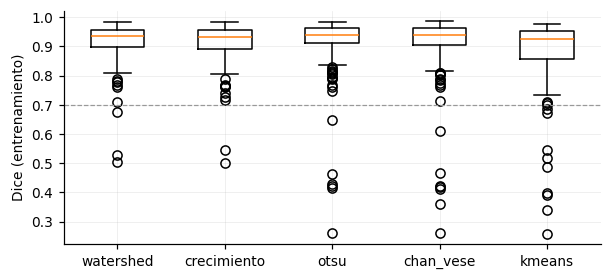

In [8]:
# Distribución del Dice de cada método (figura para el informe)
fig, ax = plt.subplots()
ax.boxplot([por_imagen[m] for m in por_imagen.columns])
ax.set_xticks(range(1, len(por_imagen.columns) + 1), por_imagen.columns)
ax.axhline(0.7, color="0.6", lw=0.8, ls="--")
ax.set_ylabel("Dice (entrenamiento)")
graficos.guardar_figura(fig, "m3_comparacion_metodos")

WindowsPath('D:/Datos Facu No Borrar/Escritorio/TP final Imágense/informe/figuras/m3_ejemplo_metodos.pdf')

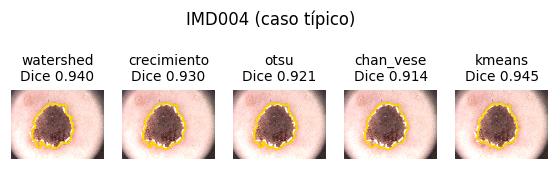

In [ ]:
# Probamos los cinco métodos, tomando la imagen cuyo Dice está más cerca de su mediana,
# que vendría a ser un "caso típico".

metodo_elegido = segmentacion.METODO_ELEGIDO
tipico = (por_imagen[metodo_elegido] - por_imagen[metodo_elegido].median()).abs().idxmin()
caso = carga_de_datos.cargar_caso(tipico, tabla)
mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)

fig, ax = plt.subplots(1, len(por_imagen.columns), figsize=(16 / 2.54, 4.5 / 2.54))
for a, metodo in zip(ax, por_imagen.columns):
    mascara = segmentacion.segmentar(mejorada, valida, metodo, **config[metodo])
    graficos.mostrar(a, caso.imagen, f"{metodo}\nDice {segmentacion.dice(mascara, caso.mascara_ref):.3f}")
    graficos.contorno(a, caso.mascara_ref, referencia=True)
    graficos.contorno(a, mascara)
fig.suptitle(f"{tipico} (caso típico)", y=1.08)
graficos.guardar_figura(fig, "m3_ejemplo_metodos")

**Resultado:** con la grilla ampliada, el orden por Dice medio es watershed (0,911), crecimiento (0,908), Otsu (0,906), Chan-Vese (0,900) y k-means (0,880).

- **Otsu y Chan-Vese** tienen la mediana más alta (0,940 y 0,938), pero tienen 6 y 7 fallas, con casos de Dice 0,26.
- **Watershed y crecimiento** tienen una mediana menor (0,936 y 0,931), pero menos fallas (3 y 2), e incluso en su peor imagen dan un Dice de 0,50.

k-means queda último en casi todo, con 10 fallas. En tiempo, todos son rápidos: el más lento es Chan-Vese, con 0,351 s por imagen, mientras que region-growing y Otsu tardan 0,016 s y 0,013 s por imagen, respectivamente.

### 2.5 ¿La diferencia es casualidad?


### 2.6 ¿Dónde falla cada método?

Se calcula el Dice medio de cada método separando las imágenes en grupos. El primer grupo es "con pelos", que ocurre si M1 marcó como pelo más del 10 % de la imagen. Por otro lado, el tamaño se divide en tres grupos, el tercio de lesiones más chicas, el del medio y el de las más grandes, cada uno con la misma cantidad de imágenes.

In [11]:
grupos = imagenes.assign(
    diagnóstico=imagenes["diagnostico"].map(carga_de_datos.DIAGNOSTICOS),
    pelos=np.where(imagenes["fraccion_pelos"] > 0.10, "con pelos (> 10 %)", "sin pelos"),
    borde=np.where(imagenes["toca_borde"], "toca el borde", "no toca el borde"),
    tamaño=pd.qcut(imagenes["fraccion_lesion"], 3, labels=["chica", "mediana", "grande"]),
)
juntos = por_imagen.join(grupos)
for columna in ["diagnóstico", "pelos", "borde", "tamaño"]:
    t = juntos.groupby(columna, observed=True)[list(por_imagen.columns)].mean()
    t.insert(0, "imágenes", juntos.groupby(columna, observed=True).size())
    display(t.round(3))

,imágenes,watershed,crecimiento,otsu,chan_vese,kmeans
diagnóstico,,,,,,
melanoma,28,0.860,0.851,0.876,0.868,0.835
nevo atípico,56,0.918,0.914,0.919,0.917,0.899
nevo común,56,0.930,0.931,0.907,0.898,0.883


,imágenes,watershed,crecimiento,otsu,chan_vese,kmeans
pelos,,,,,,
con pelos (> 10 %),30,0.879,0.873,0.873,0.866,0.855
sin pelos,110,0.920,0.918,0.914,0.909,0.887


,imágenes,watershed,crecimiento,otsu,chan_vese,kmeans
borde,,,,,,
no toca el borde,105,0.919,0.917,0.907,0.900,0.886
toca el borde,35,0.888,0.881,0.901,0.897,0.861


,imágenes,watershed,crecimiento,otsu,chan_vese,kmeans
tamaño,,,,,,
chica,47,0.920,0.922,0.879,0.866,0.85
mediana,46,0.921,0.919,0.928,0.928,0.92
grande,47,0.893,0.885,0.910,0.905,0.87


**Resultado:**

- **Tamaño.** Es lo que más separa a los métodos. En las lesiones chicas, crecimiento y watershed (0,92) le sacan 0,04 puntos a Otsu, 0,056 a Chan-Vese y 0,072 a k-means. En las grandes pasa al revés: Otsu (0,91) y Chan-Vese (0,905) quedan arriba. Esto se puede explicar porque en Otsu, cuando hay una lesión chica, el histograma casi no tiene una "montaña" de lesión y el umbral se corre hacia la piel.
- **Borde de la foto.** Cuando la lesión toca el borde, Otsu y Chan-Vese también andan mejor (0,90 contra 0,86-0,89 del resto).
- **Diagnóstico.** Los melanomas son los más difíciles para todos los métodos (entre 0,84 y 0,88), pero en los nevos comunes, crecimiento y watershed dan los valores más altos (0,93), seguido por Otsu y Chan-Vese (0,92) y por último k-means (0,899).
- **Pelos.** En todos los métodos, el rendimiento disminuye entre 0,03 y 0,05 para las 30 imágenes con pelos.

## 3. Decisión final: region-growing

Si bien Watershed tiene el mayor Dice medio (0,911), el Dice de region-growing no está tan alejado (0,908, es decir 0,011 puntos de diferencia), pero region-growing es casi diez veces más rápido (0,016 s contra 0,15 s por imagen) y, además, con una falla menos que Watershed (2 contra 3).

Así que **elegimos crecimiento de regiones**, con `sigma` = 4, tolerancia 0,5, apertura de 3 px y cierre de 10 px.

## 4. Casos difíciles del método elegido

Buscamos las tres imágenes con peor Dice usando region-growing. En blanco punteado, se grafica la segmentación de la base de datos; en amarillo, la de nuestro programa. Abajo, el Dice de los cinco métodos en esas mismas imágenes y sus características.

,watershed,crecimiento,otsu,chan_vese,kmeans,diagnostico,fraccion_pelos,fraccion_lesion,toca_borde
nombre,,,,,,,,,
IMD085,0.504,0.501,0.462,0.466,0.885,2,0.202,0.218,False
IMD425,0.529,0.545,0.649,0.609,0.487,2,0.038,0.848,True
IMD435,0.711,0.718,0.761,0.761,0.738,2,0.105,0.779,True


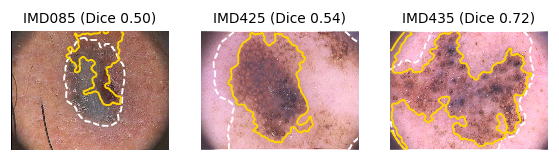

In [ ]:
elegido = segmentacion.METODO_ELEGIDO
peores = por_imagen[elegido].nsmallest(3)
fig, ax = plt.subplots(1, 3)
for a, (nombre, d) in zip(ax, peores.items()):
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
    mascara = segmentacion.segmentar(mejorada, valida, elegido, **config[elegido])
    graficos.mostrar(a, caso.imagen, f"{nombre} (Dice {d:.2f})")
    graficos.contorno(a, caso.mascara_ref, referencia=True)
    graficos.contorno(a, mascara)
graficos.guardar_figura(fig, "m3_casos_dificiles")
por_imagen.loc[peores.index].join(imagenes).round(3)

**Resultado:** los tres peores casos son melanomas, y en los tres el método deja afuera partes de la lesión que en el canal B no se ven oscuras.

- **IMD085** (Dice 0,50). Lo que queda afuera es la zona azul grisácea del centro. Un color azulado refleja bastante luz azul, así que en el canal B se ve claro, casi como la piel, y el método lo descarta. Es el único caso donde k-means anda mucho mejor (0,89), ya que como mira el color completo y no sólo el canal B, reconoce el azul grisáceo como algo distinto de la piel rosada. Es una limitación de haber segmentado sobre B, y resulta que es un problema ya que el azul grisáceo es una estructura asociada al melanoma.
- **IMD425** (0,55) e **IMD435** (0,72). Lesiones enormes (85 % y 78 % de la imagen) que se salen de la foto, con zonas pálidas y poco contraste con la piel. El método toma el núcleo oscuro, y lo pálido queda del lado de la piel.

## 5. Dice en prueba

Se corre con el método y los parámetros ya fijados en `segmentacion.py`, y es lo que usamos para el informe.

In [15]:
CORRER_PRUEBA = True
if CORRER_PRUEBA:
    dice_prueba = pd.Series({n: procesar(carga_de_datos.cargar_caso(n, tabla), hasta="segmentacion").dice
                             for n in carga_de_datos.nombres("prueba")})
    print(f"Dice en prueba ({segmentacion.METODO_ELEGIDO}, {len(dice_prueba)} imágenes): "
          f"media {dice_prueba.mean():.3f}, mediana {dice_prueba.median():.3f}, desvío {dice_prueba.std():.3f}, "
          f"peor {dice_prueba.min():.3f}, fallas (< 0,7) {(dice_prueba < 0.7).sum()}")

Dice en prueba (crecimiento, 60 imágenes): media 0.916, mediana 0.946, desvío 0.103, peor 0.300, fallas (< 0,7) 2


**Resultado:** en las 60 imágenes de prueba, crecimiento de regiones da un Dice medio de **0,916** y una mediana de **0,946**, muy parecidos a los de entrenamiento (0,908 y 0,931), aunque casi 0,01 punto mejores en ambos casos. Hay 2 fallas, que son las imágenes IMD240 (0,57) e IMD424 (0,30), los dos melanomas ya mencionados.